<a href="https://colab.research.google.com/github/keshavacta18-ui/Wine-Quality-Prediction/blob/main/3Skill_Wine_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("3Skill Wine Quality Prediction System")
print("Libraries imported successfully!")
print("Let's build our machine learning project, buddy!")

3Skill Wine Quality Prediction System
Libraries imported successfully!
Let's build our machine learning project, buddy!


In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/ashishpatel26/Wine-Quality-Prediction/master/WineQT.csv"

df = pd.read_csv(url)

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

HTTPError: HTTP Error 404: Not Found

In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/WineQT.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
    display(df.head())
    print("Dataset shape:", df.shape)
except Exception as e:
    print("Error:", e)

Error: HTTP Error 404: Not Found


In [ ]:

from google.colab import files
uploaded = files.upload()

Saving winequality-white.csv to winequality-white.csv


In [ ]:

from google.colab import files
uploaded = files.upload()

Saving winequality-red.csv to winequality-red.csv


In [ ]:

import pandas as pd

df = pd.read_csv("winequality-red.csv", sep=";")
display(df.head())
print("Dataset size:", df.shape)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Dataset size: (1599, 12)


In [ ]:


# Check the dataset before training our model

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nWine quality distribution:")
print(df["quality"].value_counts().sort_index())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values in each column:
fixed acidity           0
volatile acidity        0
citric acid          

In [ ]:


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate input features and target
X = df.drop("quality", axis=1)
y = df["quality"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model = RandomForestClassifier(
    n_estimators=200, random_state=42, class_weight="balanced"
)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)

print("Model training completed!")
print("Test accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model training completed!
Test accuracy: 66.56 %

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.72      0.74      0.73       136
           6       0.62      0.73      0.67       128
           7       0.70      0.47      0.57        40
           8       0.50      0.33      0.40         3

    accuracy                           0.67       320
   macro avg       0.42      0.38      0.39       320
weighted avg       0.64      0.67      0.65       320



In [ ]:


# Predict the quality of one wine

sample_wine = X_test.iloc[[0]]

predicted_quality = model.predict(sample_wine)[0]
actual_quality = y_test.iloc[0]

print("Predicted wine quality:", predicted_quality)
print("Actual wine quality:", actual_quality)

if predicted_quality == actual_quality:
    print("Prediction is correct!")
else:
    print("Prediction differs from actual quality.")

Predicted wine quality: 6
Actual wine quality: 6
Prediction is correct!


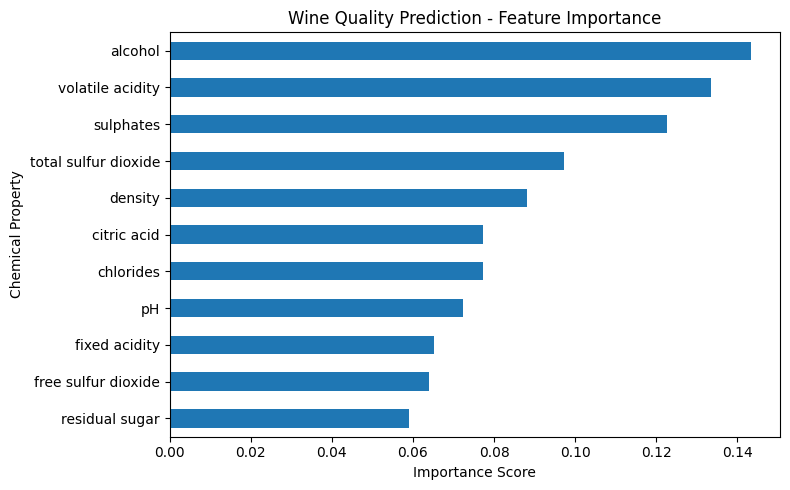

In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Wine Quality Prediction - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Property")
plt.tight_layout()
plt.show()

In [ ]:


import joblib

# Save the trained model
joblib.dump(model, "wine_quality_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:


from google.colab import files

files.download("wine_quality_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


# Predict wine quality using chemical properties

print("Enter the chemical properties of the wine:")

features = X.columns.tolist()
values = []

for feature in features:
    value = float(input(f"Enter {feature}: "))
    values.append(value)

wine_data = pd.DataFrame([values], columns=features)

prediction = model.predict(wine_data)[0]

print("\nPredicted Wine Quality:", prediction, "out of 10")

Enter the chemical properties of the wine:


KeyboardInterrupt: Interrupted by user

In [ ]:


# Test prediction using an actual row from our dataset

sample_wine = X_test.iloc[[0]]
prediction = model.predict(sample_wine)[0]

print("Wine chemical properties:")
display(sample_wine)

print("Predicted quality:", prediction)
print("Actual quality:", y_test.iloc[0])

Wine chemical properties:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
963,8.8,0.27,0.39,2.0,0.1,20.0,27.0,0.99546,3.15,0.69,11.2


Predicted quality: 6
Actual quality: 6


In [ ]:


!pip -q install gradio

import gradio as gr
import pandas as pd

def predict_wine(
    fixed_acidity, volatile_acidity, citric_acid,
    residual_sugar, chlorides, free_sulfur_dioxide,
    total_sulfur_dioxide, density, pH, sulphates, alcohol
):
    values = [[
        fixed_acidity, volatile_acidity, citric_acid,
        residual_sugar, chlorides, free_sulfur_dioxide,
        total_sulfur_dioxide, density, pH, sulphates, alcohol
    ]]

    wine = pd.DataFrame(values, columns=X.columns)
    prediction = model.predict(wine)[0]

    return f"Predicted wine quality: {prediction} / 10"

demo = gr.Interface(
    fn=predict_wine,
    inputs=[
        gr.Number(label="Fixed acidity", value=8.8),
        gr.Number(label="Volatile acidity", value=0.27),
        gr.Number(label="Citric acid", value=0.39),
        gr.Number(label="Residual sugar", value=2.0),
        gr.Number(label="Chlorides", value=0.10),
        gr.Number(label="Free sulfur dioxide", value=20),
        gr.Number(label="Total sulfur dioxide", value=27),
        gr.Number(label="Density", value=0.99546),
        gr.Number(label="pH", value=3.15),
        gr.Number(label="Sulphates", value=0.69),
        gr.Number(label="Alcohol", value=11.2)
    ],
    outputs="text",
    title="Wine Quality Prediction System",
    description="Enter the chemical properties of a wine to predict its quality."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://955fbb23270f489907.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:


readme = """
# Wine Quality Prediction System

## Project Overview
This project uses machine learning to predict wine quality
from its physicochemical properties.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- Matplotlib
- Gradio
- Google Colab

## Dataset
Wine Quality dataset.
The model uses 11 chemical properties as input features
and predicts the quality score.

## Model
Random Forest Classifier

## Test Result
Test accuracy: 66.56%

## Features
- Data inspection and missing-value checks
- Machine learning model training
- Test-set evaluation
- Feature importance visualization
- Interactive prediction interface

## How to Run
1. Open the notebook in Google Colab.
2. Load the dataset.
3. Run the model training cells.
4. Launch the Gradio interface.
5. Enter wine properties and submit to get a prediction.

## Limitation
The model's predictions are estimates based on the training
dataset and are not a guarantee of real-world wine quality.
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [ ]:

from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>